## 04 — Correlation & Multicollinearity Analysis
Ranks all ~3700 features by Spearman correlation and mutual information with AOD 550nm.
Examines inter-feature collinearity among the top-40 features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.feature_selection import mutual_info_regression

ROOT     = Path('D:/Regional-Scale-AOD-Estimation')
FEATURES = ROOT / 'feature_engineering/features/stratified'
OUT      = ROOT / 'feature_engineering/features_analysis/correlation'
OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'AOD_550nm'

In [2]:
train     = pd.read_csv(FEATURES / 'train.csv')
feat_cols = [c for c in train.columns if c != TARGET]
X_train   = train[feat_cols].values
y_train   = train[TARGET].values

assert not np.isnan(X_train).any(), "NaNs in X_train"
assert not np.isinf(X_train).any(), "Infs in X_train"
print(f'train: {train.shape} | features: {len(feat_cols)}')

train: (4099, 3701) | features: 3700


In [3]:
print('Computing Spearman correlations...')
corr_vals = np.array([spearmanr(train[c], y_train).statistic for c in feat_cols])
corr      = pd.Series(corr_vals, index=feat_cols)
corr_abs  = corr.abs().sort_values(ascending=False)

print(f'\nTop 5 features by |Spearman r|:')
for col, val in corr_abs.head(5).items():
    print(f'  {col}: |r|={val:.4f}  (r={corr[col]:.4f})')

Computing Spearman correlations...

Top 5 features by |Spearman r|:
  cratio_1_8_9: |r|=0.5673  (r=0.5673)
  cratio_0_8_9: |r|=0.5667  (r=0.5667)
  rdiff_9_12_mean: |r|=0.5627  (r=-0.5627)
  normratio_9_12: |r|=0.5606  (r=-0.5606)
  cratio_0_7_9: |r|=0.5592  (r=0.5592)


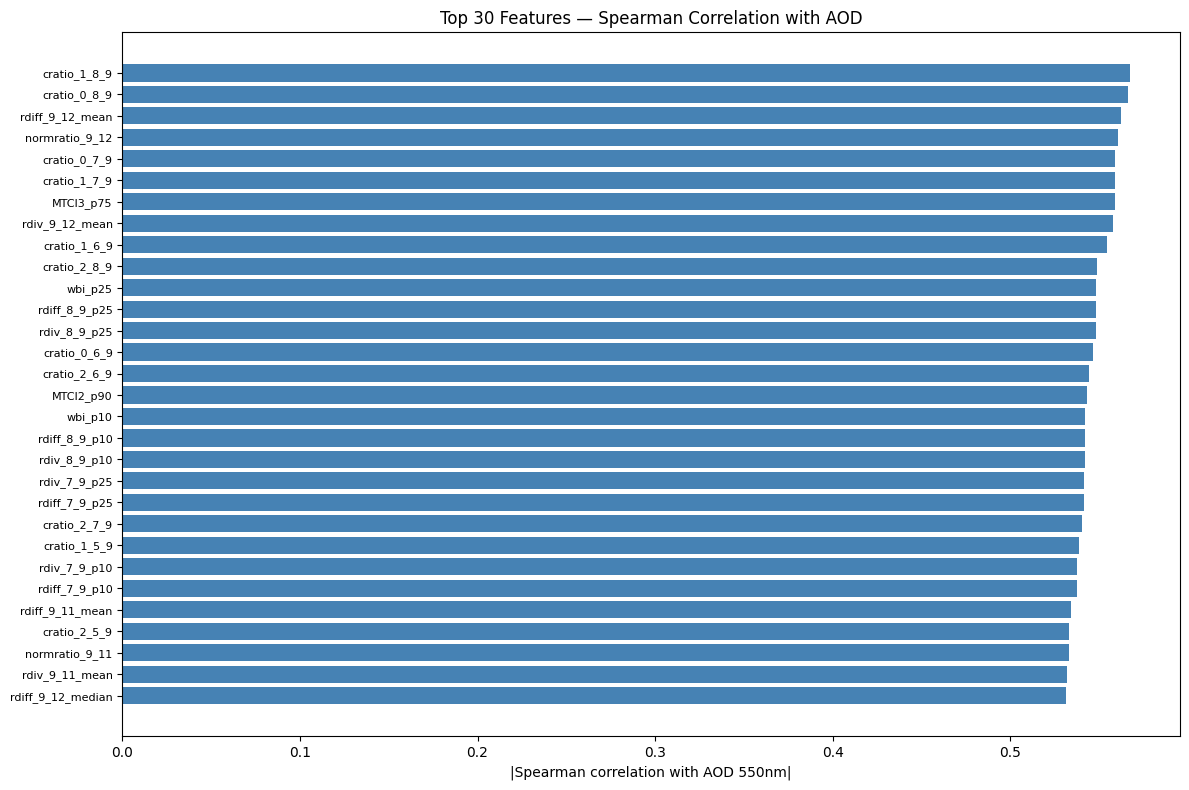

Saved: top30_spearman.png


In [4]:
top30 = corr_abs.head(30)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(top30)), top30.values, color='steelblue')
ax.set_yticks(range(len(top30)))
ax.set_yticklabels(top30.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('|Spearman correlation with AOD 550nm|')
ax.set_title('Top 30 Features — Spearman Correlation with AOD')
plt.tight_layout()
plt.savefig(OUT / 'top30_spearman.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: top30_spearman.png')

In [5]:
print('Computing mutual information (this takes ~2 minutes)...')
mi_vals = mutual_info_regression(X_train, y_train, random_state=42)
mi      = pd.Series(mi_vals, index=feat_cols).sort_values(ascending=False)

print(f'\nTop 5 features by mutual information:')
for col, val in mi.head(5).items():
    print(f'  {col}: MI={val:.4f}')

Computing mutual information (this takes ~2 minutes)...

Top 5 features by mutual information:
  rdiff_0_1_std: MI=0.3529
  rdiff_0_1_var: MI=0.3529
  r04_std: MI=0.3524
  r04_var: MI=0.3524
  rdiv_0_1_var: MI=0.3514


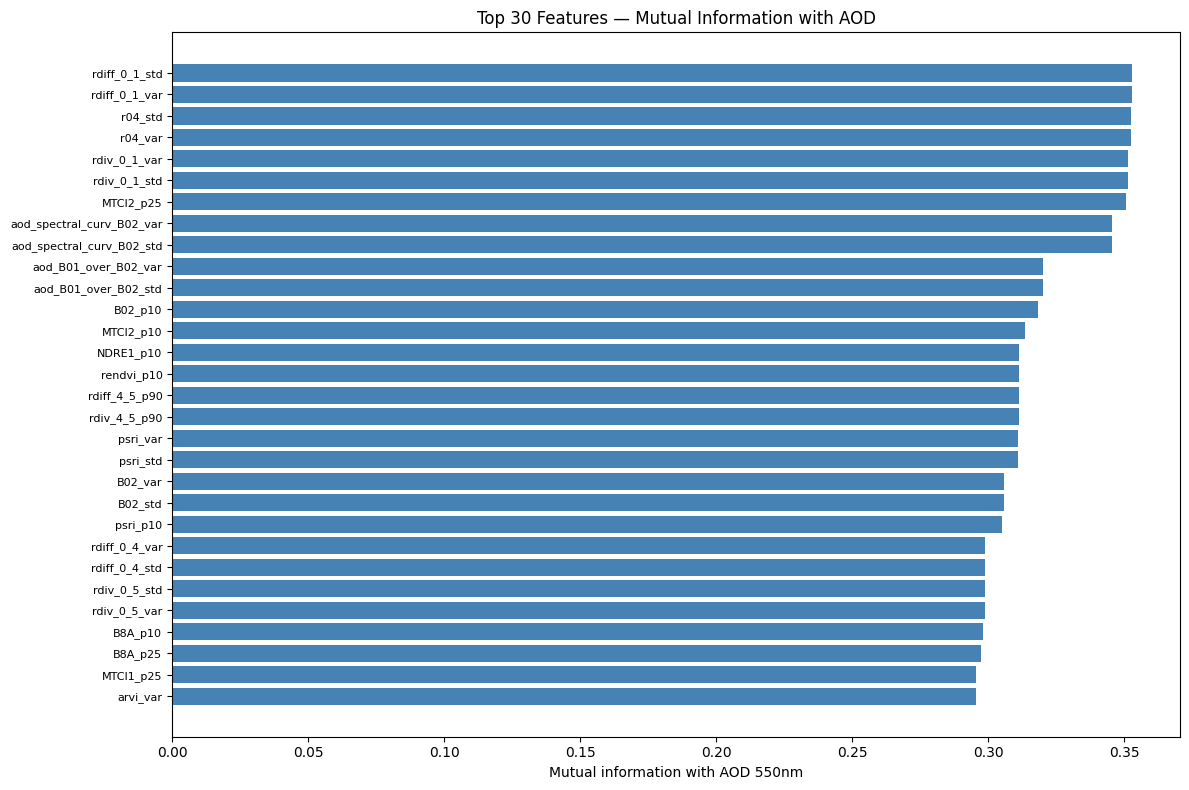

Saved: top30_mi.png


In [6]:
top30_mi = mi.head(30)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(range(len(top30_mi)), top30_mi.values, color='steelblue')
ax.set_yticks(range(len(top30_mi)))
ax.set_yticklabels(top30_mi.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('Mutual information with AOD 550nm')
ax.set_title('Top 30 Features — Mutual Information with AOD')
plt.tight_layout()
plt.savefig(OUT / 'top30_mi.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: top30_mi.png')

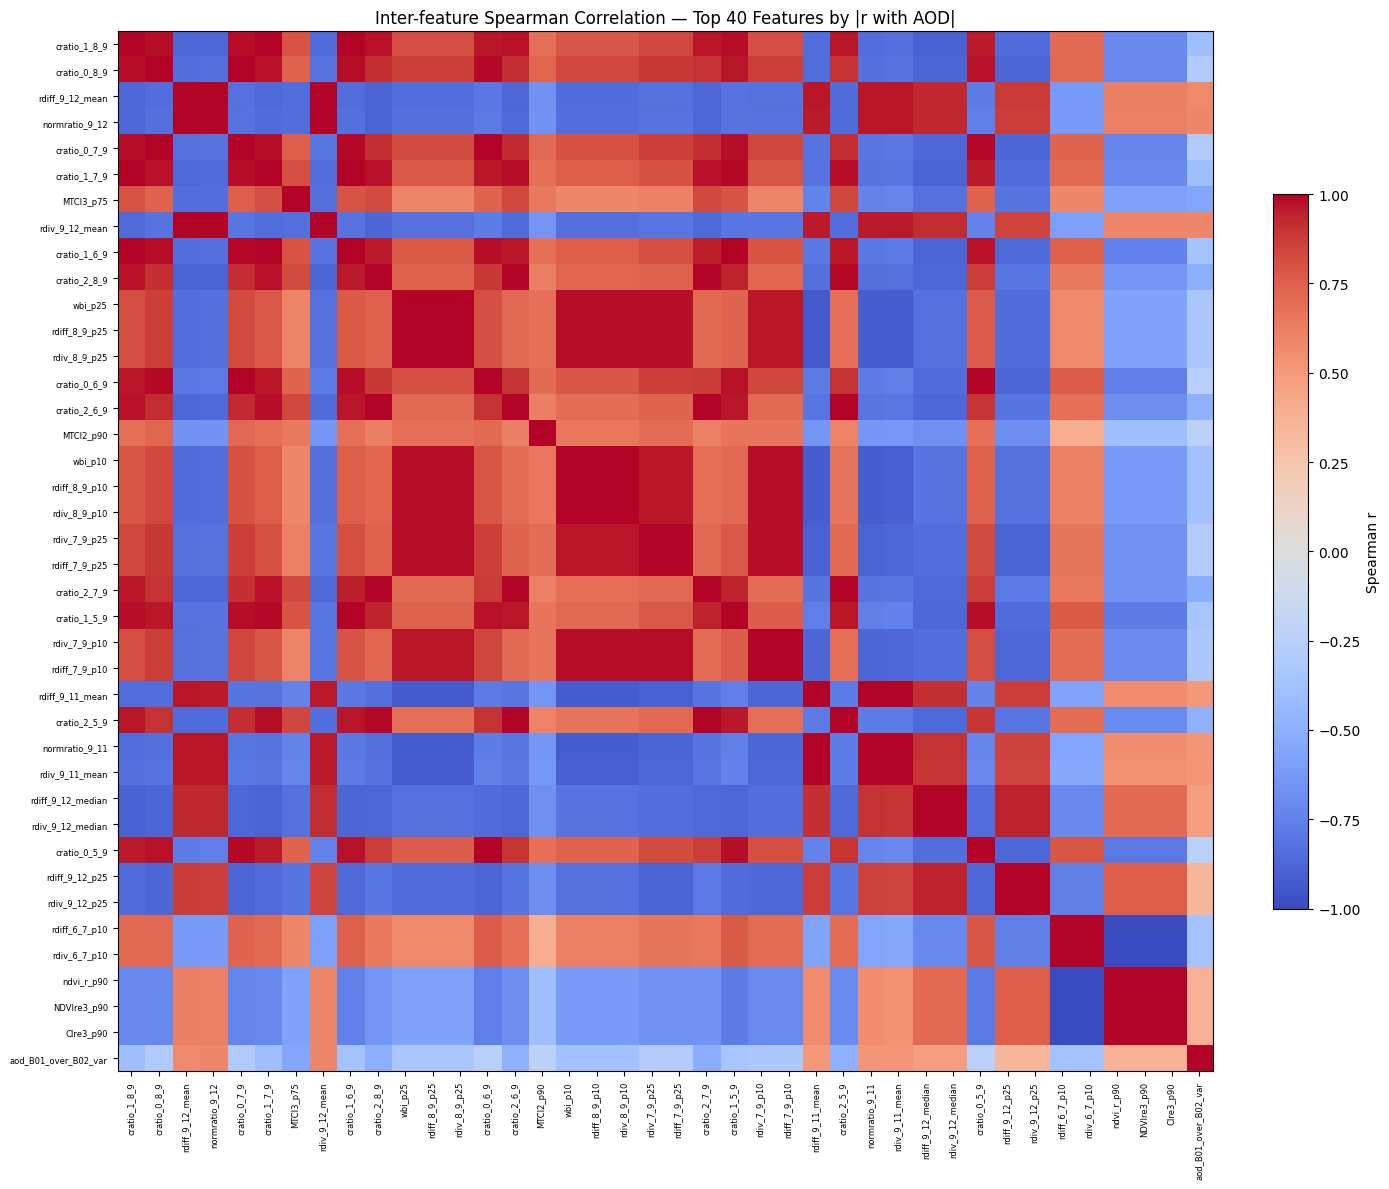

Saved: inter_feature_correlation.png

Pairs with |r| >= 0.95: 120
        feature_a        feature_b  spearman_r
          wbi_p25    rdiff_8_9_p25         1.0
          wbi_p25     rdiv_8_9_p25         1.0
    rdiff_6_7_p10     rdiv_6_7_p10         1.0
    rdiff_6_7_p10       ndvi_r_p90        -1.0
          wbi_p10     rdiv_8_9_p10         1.0
    rdiff_8_9_p10     rdiv_8_9_p10         1.0
rdiff_9_12_median rdiv_9_12_median         1.0
     rdiv_7_9_p10    rdiff_7_9_p10         1.0
     rdiv_7_9_p25    rdiff_7_9_p25         1.0
    rdiff_6_7_p10        CIre3_p90        -1.0


In [7]:
top40_cols  = corr_abs.head(40).index.tolist()
corr_matrix = train[top40_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, fraction=0.03, label='Spearman r')
ax.set_xticks(range(len(top40_cols)))
ax.set_yticks(range(len(top40_cols)))
ax.set_xticklabels(top40_cols, rotation=90, fontsize=6)
ax.set_yticklabels(top40_cols, fontsize=6)
ax.set_title('Inter-feature Spearman Correlation — Top 40 Features by |r with AOD|')
plt.tight_layout()
plt.savefig(OUT / 'inter_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: inter_feature_correlation.png')

# Report highly collinear pairs
threshold = 0.95
pairs = []
for i in range(len(top40_cols)):
    for j in range(i + 1, len(top40_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) >= threshold:
            pairs.append({'feature_a': top40_cols[i],
                          'feature_b': top40_cols[j],
                          'spearman_r': round(r, 4)})
pairs_df = pd.DataFrame(pairs, columns=['feature_a', 'feature_b', 'spearman_r']).sort_values('spearman_r', key=abs, ascending=False)
print(f'\nPairs with |r| >= {threshold}: {len(pairs_df)}')
if len(pairs_df) > 0:
    print(pairs_df.head(10).to_string(index=False))

In [8]:
corr_df = pd.DataFrame({
    'feature':        corr_abs.index,
    'spearman_r_abs': corr_abs.values,
    'spearman_r':     corr[corr_abs.index].values,
})
corr_df.to_csv(OUT / 'spearman_all.csv', index=False)

mi_df = pd.DataFrame({'feature': mi.index, 'mutual_info': mi.values})
mi_df.to_csv(OUT / 'mutual_info_all.csv', index=False)

pairs_df.to_csv(OUT / 'high_corr_pairs.csv', index=False)

print('Saved:')
print(f'  spearman_all.csv    ({len(corr_df)} rows)')
print(f'  mutual_info_all.csv ({len(mi_df)} rows)')
print(f'  high_corr_pairs.csv ({len(pairs_df)} rows)')

Saved:
  spearman_all.csv    (3700 rows)
  mutual_info_all.csv (3700 rows)
  high_corr_pairs.csv (120 rows)
